# 02 · Product Metrics & Opportunity Sizing

**Question for this notebook:** where is the growth opportunity in Olist's marketplace, and is a cross-sell feature ("Smart Basket") worth testing?

Metric definitions are in [`docs/02_Metrics_Definition.md`](../docs/02_Metrics_Definition.md). Unless stated otherwise, every number covers **non-canceled orders, Jan 2017 – Aug 2018**.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smart_basket import config, data_model as dm, plotting as P
from smart_basket.recommender import CategoryAffinityRecommender, evaluation_cases, hit_rate

P.use_style()
pd.set_option("display.float_format", "{:,.2f}".format)

t = dm.load_tables()
orders_all, items_all = t["orders"], t["order_items"]
in_window = orders_all["purchased_at"].between(config.ANALYSIS_START, config.ANALYSIS_END + " 23:59:59")
orders = orders_all[in_window & ~orders_all["is_canceled"]].copy()
items = items_all[items_all["order_id"].isin(orders["order_id"])].merge(
    orders[["order_id", "customer_unique_id", "purchased_at"]], on="order_id"
)
print(f"{len(orders):,} orders · {orders['customer_unique_id'].nunique():,} customers · {len(items):,} order lines")

97,905 orders · 94,703 customers · 111,752 order lines


## 1. KPI snapshot

In [2]:
cust = orders.groupby("customer_unique_id").agg(orders=("order_id", "size"), gmv=("gmv", "sum"))
kpi = {
    "GMV (R$)": orders["gmv"].sum(),
    "Orders": len(orders),
    "Customers": len(cust),
    "AOV (R$)": orders["gmv"].mean(),
    "Median order value (R$)": orders["gmv"].median(),
    "Items per order": orders["items_count"].mean(),
    "Multi-product order rate": orders["is_multi_product"].mean(),
    "Multi-category order rate": (orders["distinct_categories"] > 1).mean(),
    "Repeat-customer rate": (cust["orders"] > 1).mean(),
    "Average review score": orders["review_score"].mean(),
    "Late-delivery rate": orders["is_late"].astype(float).mean(),
    "Median delivery time (days)": orders["delivery_days"].median(),
}
fmt = {k: ("{:.1%}" if "rate" in k else "{:,.0f}" if k in ("GMV (R$)", "Orders", "Customers") else "{:,.2f}") for k in kpi}
pd.Series({k: fmt[k].format(v) for k, v in kpi.items()}).to_frame("value")

,value
GMV (R$),"15,683,707"
Orders,"97,905"
Customers,"94,703"
AOV (R$),160.19
Median order value (R$),105.28
Items per order,1.14
Multi-product order rate,3.3%
Multi-category order rate,0.8%
Repeat-customer rate,3.0%
Average review score,4.12


## 2. Growth: volume is up, order value is flat

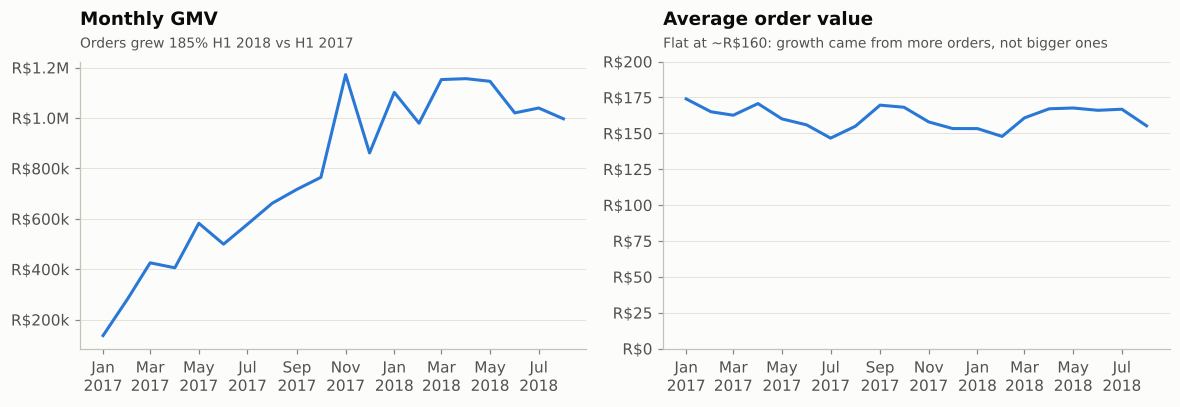

In [3]:
monthly = orders.groupby("purchase_month").agg(orders=("order_id", "size"), gmv=("gmv", "sum"), aov=("gmv", "mean"))
h1_growth = monthly.loc["2018-01":"2018-06", "orders"].sum() / monthly.loc["2017-01":"2017-06", "orders"].sum() - 1

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(monthly.index, monthly["gmv"], color=P.SERIES[0])
axes[0].yaxis.set_major_formatter(P.BRL)
P.titled(axes[0], "Monthly GMV", f"Orders grew {h1_growth:.0%} H1 2018 vs H1 2017")
axes[1].plot(monthly.index, monthly["aov"], color=P.SERIES[0])
axes[1].set_ylim(0, 200)
axes[1].yaxis.set_major_formatter(P.BRL)
P.titled(axes[1], "Average order value", "Flat at ~R$160: growth came from more orders, not bigger ones")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
fig.tight_layout()
P.save(fig, "01_growth")
plt.show()

## 3. Customers: almost nobody comes back

In [4]:
repeat = cust["orders"] > 1
sorted_gmv = cust["gmv"].sort_values(ascending=False)
top10_share = sorted_gmv.head(int(len(sorted_gmv) * 0.10)).sum() / sorted_gmv.sum()

seq = orders.sort_values("purchased_at").copy()
seq["n"] = seq.groupby("customer_unique_id").cumcount() + 1
first = seq[seq["n"] == 1].set_index("customer_unique_id")["purchased_at"]
second = seq[seq["n"] == 2].set_index("customer_unique_id")["purchased_at"]
gap_days = (second - first.loc[second.index]).dt.days

customer_facts = pd.Series(
    {
        "repeat-customer rate": f"{repeat.mean():.1%}",
        "share of GMV from repeat customers": f"{cust.loc[repeat, 'gmv'].sum() / cust['gmv'].sum():.1%}",
        "avg customer GMV: one-time": f"R${cust.loc[~repeat, 'gmv'].mean():,.0f}",
        "avg customer GMV: repeat": f"R${cust.loc[repeat, 'gmv'].mean():,.0f}",
        "GMV share of top 10% customers": f"{top10_share:.1%}",
        "median days to 2nd order": f"{gap_days.median():.0f}",
        "2nd orders placed the SAME DAY as the 1st": f"{(gap_days == 0).mean():.1%}",
    }
)
customer_facts.to_frame("value")

,value
repeat-customer rate,3.0%
share of GMV from repeat customers,5.7%
avg customer GMV: one-time,R$161
avg customer GMV: repeat,R$308
GMV share of top 10% customers,38.3%
median days to 2nd order,28
2nd orders placed the SAME DAY as the 1st,31.1%


**A key finding:** almost a third of "repeat" purchases happen *on the same day* as the first order. These customers aren't returning months later; they come straight back to buy something they could have added to the original basket. That's direct evidence of unmet cross-sell demand at checkout.

Monthly cohort retention shows the same thing: after month 0, retention stays below 1% in every month.

In [5]:
cohorts = orders.merge(t["customers"][["customer_unique_id", "cohort_month"]], on="customer_unique_id")
cohorts["age"] = (cohorts["purchase_month"].dt.year - cohorts["cohort_month"].dt.year) * 12 + (
    cohorts["purchase_month"].dt.month - cohorts["cohort_month"].dt.month
)
grid = cohorts.groupby(["cohort_month", "age"])["customer_unique_id"].nunique().unstack()
retention = grid.div(grid[0], axis=0).loc["2017-01":"2018-02", 1:6]
retention.index = retention.index.strftime("%b %Y")
retention.columns = [f"M{c}" for c in retention.columns]
retention.style.format("{:.2%}").background_gradient(cmap="Blues", vmin=0, vmax=0.01)

,M1,M2,M3,M4,M5,M6
cohort_month,,,,,,
Jan 2017,0.40%,0.27%,0.13%,0.40%,0.13%,0.40%
Feb 2017,0.24%,0.30%,0.12%,0.41%,0.12%,0.24%
Mar 2017,0.51%,0.35%,0.39%,0.35%,0.16%,0.16%
Apr 2017,0.60%,0.22%,0.17%,0.30%,0.26%,0.34%
May 2017,0.48%,0.48%,0.40%,0.31%,0.34%,0.42%
Jun 2017,0.45%,0.35%,0.39%,0.26%,0.39%,0.35%
Jul 2017,0.52%,0.34%,0.24%,0.29%,0.21%,0.31%
Aug 2017,0.68%,0.34%,0.27%,0.36%,0.53%,0.29%
Sep 2017,0.69%,0.54%,0.29%,0.44%,0.22%,0.22%


## 4. Baskets: single-item orders dominate, and multi-product orders are worth 55% more

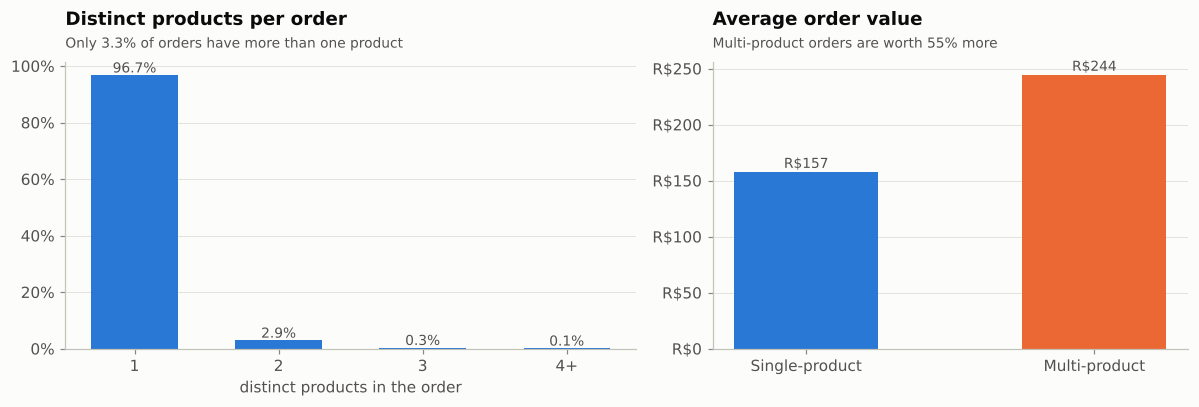

In [6]:
mp = orders.groupby("is_multi_product")["gmv"].mean()
basket_uplift = mp[True] / mp[False] - 1

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
dist = orders["distinct_products"].clip(upper=4).value_counts(normalize=True).sort_index()
axes[0].bar(["1", "2", "3", "4+"], dist.values, color=P.SERIES[0], width=0.6)
axes[0].yaxis.set_major_formatter(P.PCT)
for i, v in enumerate(dist.values):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=9, color=P.INK_2)
axes[0].set_xlabel("distinct products in the order")
P.titled(axes[0], "Distinct products per order", f"Only {orders['is_multi_product'].mean():.1%} of orders have more than one product")

axes[1].bar(["Single-product", "Multi-product"], mp.values, color=[P.SERIES[0], P.SERIES[1]], width=0.5)
axes[1].yaxis.set_major_formatter(P.BRL)
for i, v in enumerate(mp.values):
    axes[1].text(i, v + 4, f"R${v:,.0f}", ha="center", fontsize=9, color=P.INK_2)
P.titled(axes[1], "Average order value", f"Multi-product orders are worth {basket_uplift:.0%} more")
fig.tight_layout()
P.save(fig, "02_basket")
plt.show()

In [7]:
by_cat = (
    orders.groupby("primary_category")
    .agg(orders=("order_id", "size"), gmv=("gmv", "sum"), multi_product_rate=("is_multi_product", "mean"), review=("review_score", "mean"))
    .sort_values("gmv", ascending=False)
)
by_cat["gmv_share"] = by_cat["gmv"] / by_cat["gmv"].sum()
print(f"Top 10 of {len(by_cat)} categories = {by_cat['gmv_share'].head(10).sum():.0%} of GMV")
by_cat.head(10)[["orders", "gmv", "gmv_share", "multi_product_rate", "review"]].style.format(
    {"orders": "{:,.0f}", "gmv": "R${:,.0f}", "gmv_share": "{:.1%}", "multi_product_rate": "{:.1%}", "review": "{:.2f}"}
)

Top 10 of 74 categories = 62% of GMV


,orders,gmv,gmv_share,multi_product_rate,review
primary_category,,,,,
health_beauty,"8,723","R$1,433,024",9.1%,2.3%,4.20
watches_gifts,"5,582","R$1,296,138",8.3%,3.1%,4.08
bed_bath_table,"9,306","R$1,240,919",7.9%,7.6%,3.98
sports_leisure,"7,619","R$1,144,189",7.3%,2.1%,4.19
computers_accessories,"6,617","R$1,049,018",6.7%,3.1%,4.04
furniture_decor,"6,255","R$889,284",5.7%,5.1%,4.04
housewares,"5,775","R$769,991",4.9%,2.9%,4.17
cool_stuff,"3,580","R$703,219",4.5%,1.8%,4.19
auto,"3,846","R$677,210",4.3%,2.7%,4.11


Home categories (`bed_bath_table`, `furniture_decor`) already have 2× the average multi-product rate; people furnish a room in one go. Electronics and gifts are almost always single-item. This shapes the recommender: complementary home categories are the obvious first win.

## 5. Customer experience: late delivery is what kills satisfaction

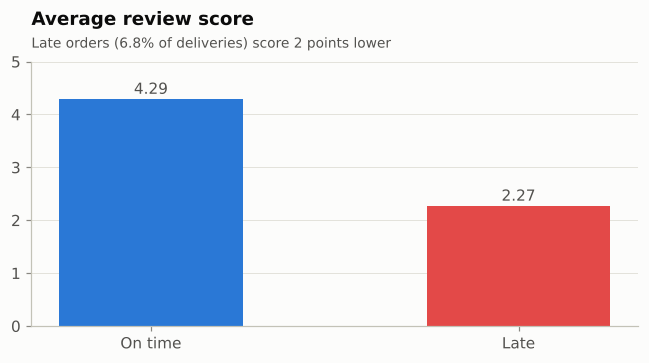

In [8]:
late = orders.dropna(subset=["is_late"]).groupby("is_late")["review_score"].agg(["mean", "size"])
late.index = ["On time", "Late"]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(late.index, late["mean"], color=[P.SERIES[0], P.SERIES[7]], width=0.5)
ax.set_ylim(0, 5)
for i, v in enumerate(late["mean"]):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=10, color=P.INK_2)
P.titled(ax, "Average review score", f"Late orders ({orders['is_late'].astype(float).mean():.1%} of deliveries) score 2 points lower")
fig.tight_layout()
P.save(fig, "03_late_delivery")
plt.show()

**Implication for Smart Basket:** an extra item from a *different seller* can ship separately and arrive late. Review score and late-delivery rate must be **guardrail metrics** in the experiment. A feature that adds revenue but damages delivery experience isn't a win.

## 6. Smart Basket v1: a category-affinity recommender

Logic: for the category in the cart, recommend the 3 categories most often bought **together with it**, either in the same order or by the same customer. It's simple, explainable and cheap to serve.

**Offline evaluation:** train on data before 5 Mar 2018 (the experiment start), test on purchases after it. For every real case where a customer bought category A *and* another category, did the top-k recommendations for A include one of them? We compare against a "most popular categories" baseline.

In [9]:
cutoff = pd.Timestamp("2018-03-05")
lines_all = items_all.merge(orders_all[["order_id", "customer_unique_id", "purchased_at", "is_canceled"]], on="order_id")
lines_all = lines_all[~lines_all["is_canceled"]]
train, test = lines_all[lines_all["purchased_at"] < cutoff], lines_all[lines_all["purchased_at"] >= cutoff]

model = CategoryAffinityRecommender(k=3).fit(train)
cases = evaluation_cases(test)
offline = pd.DataFrame(
    {f"hit@{k}": {"Smart Basket (affinity)": hit_rate(model, cases, k), "Popularity baseline": hit_rate(model, cases, k, baseline=True)} for k in (1, 3, 5)}
)
offline.loc["Relative improvement"] = offline.iloc[0] / offline.iloc[1] - 1
print(f"{len(cases):,} test cases")
offline.style.format("{:.1%}")

1,958 test cases


,hit@1,hit@3,hit@5
Smart Basket (affinity),16.2%,36.7%,47.1%
Popularity baseline,10.6%,31.1%,44.1%
Relative improvement,53.6%,18.1%,7.0%


In [10]:
top_rules = model.co_[model.co_["co_purchases"] >= 20].sort_values("lift", ascending=False).head(10)
top_rules[["anchor", "recommended", "co_purchases", "confidence", "lift"]].style.format(
    {"confidence": "{:.0%}", "lift": "{:.1f}×"}
).hide(axis="index")

anchor,recommended,co_purchases,confidence,lift
bed_bath_table,home_confort,79,16%,34.4×
toys,baby,35,24%,9.4×
cool_stuff,baby,40,23%,9.0×
home_confort,bed_bath_table,79,78%,7.6×
baby,cool_stuff,40,26%,6.1×
baby,toys,35,23%,5.1×
bed_bath_table,furniture_decor,174,36%,4.5×
furniture_decor,bed_bath_table,174,41%,4.0×
housewares,furniture_decor,50,22%,2.8×
garden_tools,furniture_decor,31,22%,2.7×


The recommender beats popularity at every k, but the margin is modest (about +18% relative at k=3). That's an honest v1: good enough to justify an experiment, with obvious upgrades ready (product-level rules, seller co-location, price matching).

## 7. Opportunity sizing: is it worth an experiment?

In [11]:
last12 = orders[orders["purchased_at"] >= "2017-09-01"]
annual_orders = len(last12)
incremental_value = mp[True] - mp[False]
sizing = pd.DataFrame(
    {"lift in multi-product rate (pp)": [0.5, 0.8, 1.0, 2.0]}
)
sizing["extra multi-product orders / year"] = (sizing.iloc[:, 0] / 100 * annual_orders).round()
sizing["incremental GMV / year (R$)"] = sizing["extra multi-product orders / year"] * incremental_value
sizing["GMV lift"] = sizing["incremental GMV / year (R$)"] / last12["gmv"].sum()
print(f"Basis: {annual_orders:,} orders in the last 12 months, R${incremental_value:,.0f} extra GMV per multi-product order")
sizing.style.format({"extra multi-product orders / year": "{:,.0f}", "incremental GMV / year (R$)": "R${:,.0f}", "GMV lift": "{:.2%}"}).hide(axis="index")

Basis: 75,343 orders in the last 12 months, R$87 extra GMV per multi-product order


lift in multi-product rate (pp),extra multi-product orders / year,incremental GMV / year (R$),GMV lift
0.500000,377,"R$32,682",0.27%
0.800000,603,"R$52,273",0.43%
1.000000,753,"R$65,277",0.54%
2.000000,"1,507","R$130,640",1.08%


A +0.8 pp lift (the smallest effect our traffic can reliably detect in ~11 weeks; see notebook 03) is worth roughly **R$52k of GMV a year**, about 0.4%. That's small but cheap to build, and the bigger prize is upstream: getting customers into the habit of building baskets is the main lever on a 3% repeat rate.

## 8. Save outputs for the dashboard and README

In [12]:
config.REPORTS_DIR.mkdir(exist_ok=True)
summary = {
    "window": f"{config.ANALYSIS_START} to {config.ANALYSIS_END}",
    "kpis": {k: float(v) for k, v in kpi.items()},
    "h1_order_growth": float(h1_growth),
    "repeat_gmv_share": float(cust.loc[repeat, "gmv"].sum() / cust["gmv"].sum()),
    "clv_one_time": float(cust.loc[~repeat, "gmv"].mean()),
    "clv_repeat": float(cust.loc[repeat, "gmv"].mean()),
    "top10_customer_gmv_share": float(top10_share),
    "same_day_second_order_share": float((gap_days == 0).mean()),
    "median_days_to_second_order": float(gap_days.median()),
    "aov_single_product": float(mp[False]),
    "aov_multi_product": float(mp[True]),
    "multi_product_aov_uplift": float(basket_uplift),
    "review_on_time": float(late.loc["On time", "mean"]),
    "review_late": float(late.loc["Late", "mean"]),
    "top10_category_gmv_share": float(by_cat["gmv_share"].head(10).sum()),
    "n_categories": int(len(by_cat)),
    "offline_hit_at_3": float(offline.loc["Smart Basket (affinity)", "hit@3"]),
    "offline_hit_at_3_baseline": float(offline.loc["Popularity baseline", "hit@3"]),
    "annual_orders": int(annual_orders),
    "gmv_per_extra_multi_product_order": float(incremental_value),
}
(config.REPORTS_DIR / "metrics_summary.json").write_text(json.dumps(summary, indent=2))
monthly.reset_index().to_csv(config.REPORTS_DIR / "monthly_kpis.csv", index=False)
by_cat.reset_index().to_csv(config.REPORTS_DIR / "category_kpis.csv", index=False)
retention.to_csv(config.REPORTS_DIR / "cohort_retention.csv")
top_rules.to_csv(config.REPORTS_DIR / "top_affinity_rules.csv", index=False)
print("saved:", sorted(p.name for p in config.REPORTS_DIR.iterdir()))

saved: ['category_kpis.csv', 'cohort_retention.csv', 'experiment_results.json', 'metrics_summary.json', 'monthly_kpis.csv', 'top_affinity_rules.csv']


## Key insights

1. **Growth is volume-driven.** Orders grew 185% (H1 2018 vs H1 2017) while AOV stayed flat at ~R$160. Basket size is an untouched lever.
2. **Baskets are tiny.** Only ~3% of orders contain more than one product, but those orders are worth ~55% more.
3. **Retention is the structural problem.** Only 3% of customers ever buy twice, and ~31% of those second purchases happen the same day as the first, which is cross-sell demand the checkout failed to capture.
4. **Revenue is concentrated.** The top 10% of customers bring ~38% of GMV, and the top 10 categories ~62%.
5. **Delivery reliability drives satisfaction.** Late orders score ~2.3 vs ~4.3, so anything that adds shipments needs a delivery guardrail.
6. **A simple affinity recommender beats popularity offline**, which is enough evidence to run a controlled experiment (notebook 03).